# Project01 Dữ liệu và huấn luyện MLP

Notebook này đọc **24.000 dòng đã đóng gói**, kiểm tra chia tập, huấn luyện MLP PyTorch và ba đối chứng, chọn model/ngưỡng trên validation rồi đánh giá test.

**Cách chạy:** cài `requirements.txt`, chọn kernel Python 3.11 của môi trường đó, Run All. Không có cell tự cài thư viện. Các cell gọi mã thật trong `diabetes_agent/models.py`; source nằm cùng gói, không phụ thuộc workspace khác.

**Giới hạn:** nhãn khảo sát gộp theo UCI, không phải chẩn đoán type 2 hoặc dự báo bệnh tương lai. Dữ liệu được kế thừa từ tập nghiên cứu cũ trong workspace; model được huấn luyện mới cho Project01.

In [1]:
# Chạy được khi kernel bắt đầu ở PROJECT_01 hoặc notebooks.
import sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "diabetes_agent").exists() else Path.cwd().parent
assert (ROOT / "diabetes_agent").exists(), "Mở notebook từ thư mục PROJECT_01"
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image
from diabetes_agent.config import ARTIFACTS, DATA, FEATURES
print("Python:", sys.version.split()[0], "| Project:", ROOT.name)

Python: 3.11.9 | Project: PROJECT_01


## 1 Kiểm tra nguồn và tính toàn vẹn
SHA256 phải khớp provenance. Fingerprint của cùng vector đặc trưng không được xuất hiện ở hai split; đây không phải bảo đảm nhận dạng người tham gia khi thiếu ID người bệnh.

In [2]:
import json
from diabetes_agent.data import load_data, build_database
frame = load_data()
display(frame.groupby("split").target.agg(["count", "mean"]))
print("Đặc trưng:", FEATURES)
display(frame[FEATURES + ["target", "split"]].head())
provenance = json.loads((DATA / "provenance.json").read_text(encoding="utf-8"))
print("Nguồn:", provenance["source"])
print("SHA256:", provenance["study_sha256"])

,count,mean
split,,
test,3612,0.137320
train,16787,0.141479
validation,3601,0.131352


Đặc trưng: ['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,target,split
0,0,0,1,31,1,0,0,0,0,1,...,4,30,30,1,1,2,3,1,0,train
1,1,1,1,24,1,0,0,1,0,1,...,3,0,2,0,1,9,3,7,0,test
2,1,1,1,40,0,0,0,0,1,1,...,3,0,14,0,0,10,4,3,0,train
3,0,1,1,27,1,0,0,1,1,1,...,2,0,3,0,1,10,6,7,0,train
4,0,0,1,23,0,0,0,1,1,1,...,4,5,15,0,1,7,5,2,0,train


Nguồn: https://archive.ics.uci.edu/dataset/891/cdc+diabetes+health+indicators
SHA256: 9fb446f2ace1fc4965067accbda303b6e0c92887c665a90693b1ff1955a8cd12


## 2 Tạo CSDL SQLite và kiểm tra phân bố
CSDL được dựng lại từ CSV. Bảng chỉ lưu dữ liệu nghiên cứu công khai. Target, row_id, group và split không được đưa vào input model.

,count,mean
split,,
test,3612,0.137320
train,16787,0.141479
validation,3601,0.131352


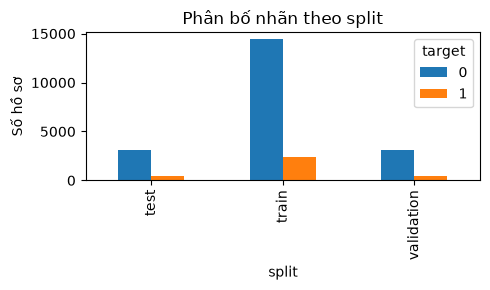

In [3]:
display(build_database())
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(5, 3))
frame.groupby(["split", "target"]).size().unstack().plot.bar(ax=ax)
ax.set_ylabel("Số hồ sơ"); ax.set_title("Phân bố nhãn theo split")
plt.tight_layout(); display(fig); plt.close(fig)

## 3 Mô hình và quy trình học

MLP: $21 \to 64 \to 32 \to 1$, ReLU, dropout 0.15, Adam learning rate 0.001, batch 256. Hàm loss là BCE với logit; không cân bằng lại nhãn nên không tuyên bố hiệu chỉnh về một dân số khác. Scaler chỉ fit train. Early stopping xem BCE validation, patience 10, tối đa 80 epoch. Hai mô hình đối chứng học là Logistic Regression và Random Forest; Dummy chỉ dùng tiên nghiệm train.

**Quy tắc khóa trước test:** chọn mặc định bằng Average Precision validation; mỗi ngưỡng tối ưu F1 trên validation. Test không được dùng để thay cấu hình. Một split/seed supervised chưa đủ để suy rộng kết quả.

In [4]:
# Xem trực tiếp kiến trúc thực thi, không phải pseudocode.
from diabetes_agent.models import architecture
print(architecture())

Sequential(
  (0): Linear(in_features=21, out_features=64, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.15, inplace=False)
  (3): Linear(in_features=64, out_features=32, bias=True)
  (4): ReLU()
  (5): Linear(in_features=32, out_features=1, bias=True)
)


In [5]:
# Fit thật, lưu weight/scaler, quyết định validation, rồi xuất test predictions.
from diabetes_agent.models import train_all
test_metrics, manifest = train_all()
display(pd.read_csv(ARTIFACTS / "metrics_validation.csv"))
print("Mặc định đã chọn bằng validation:", manifest["default_model"])
print("Epoch MLP được chọn:", manifest["best_epoch"])

,model,roc_auc,average_precision,f1,precision,recall,specificity,brier,threshold,tn,fp,fn,tp
0,dummy,0.500000,0.131352,0.232204,0.131352,1.000000,0.000000,0.114201,0.050,0,3128,0,473
1,logistic,0.812739,0.348209,0.434981,0.339667,0.604651,0.822251,0.098623,0.215,2572,556,187,286
2,random_forest,0.810360,0.371311,0.438662,0.338303,0.623679,0.815537,0.096658,0.230,2551,577,178,295
3,mlp,0.816985,0.370597,0.441360,0.328512,0.672304,0.792199,0.095996,0.205,2478,650,155,318


Mặc định đã chọn bằng validation: random_forest
Epoch MLP được chọn: 21


## 4 Đọc output huấn luyện và test
Recall và precision phải đọc cùng nhau. Tập mất cân bằng khiến accuracy dễ gây hiểu nhầm; Average Precision có đường chuẩn bằng tỷ lệ nhãn 1.

,model,roc_auc,average_precision,f1,precision,recall,specificity,brier,threshold,tn,fp,fn,tp
0,dummy,0.5000,0.1373,0.2415,0.1373,1.0000,0.0000,0.1185,0.050,0,3116,0,496
1,logistic,0.8118,0.3820,0.4367,0.3499,0.5806,0.8283,0.1003,0.215,2581,535,208,288
2,random_forest,0.8096,0.3906,0.4534,0.3564,0.6230,0.8209,0.0993,0.230,2558,558,187,309
3,mlp,0.8168,0.3916,0.4431,0.3358,0.6512,0.7949,0.0987,0.205,2477,639,173,323


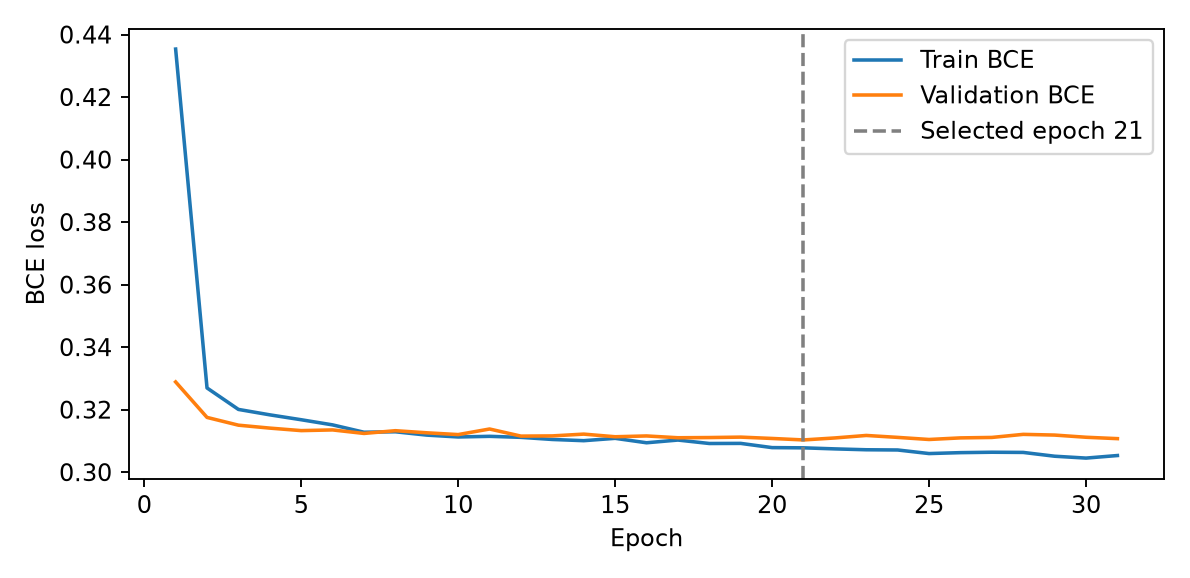

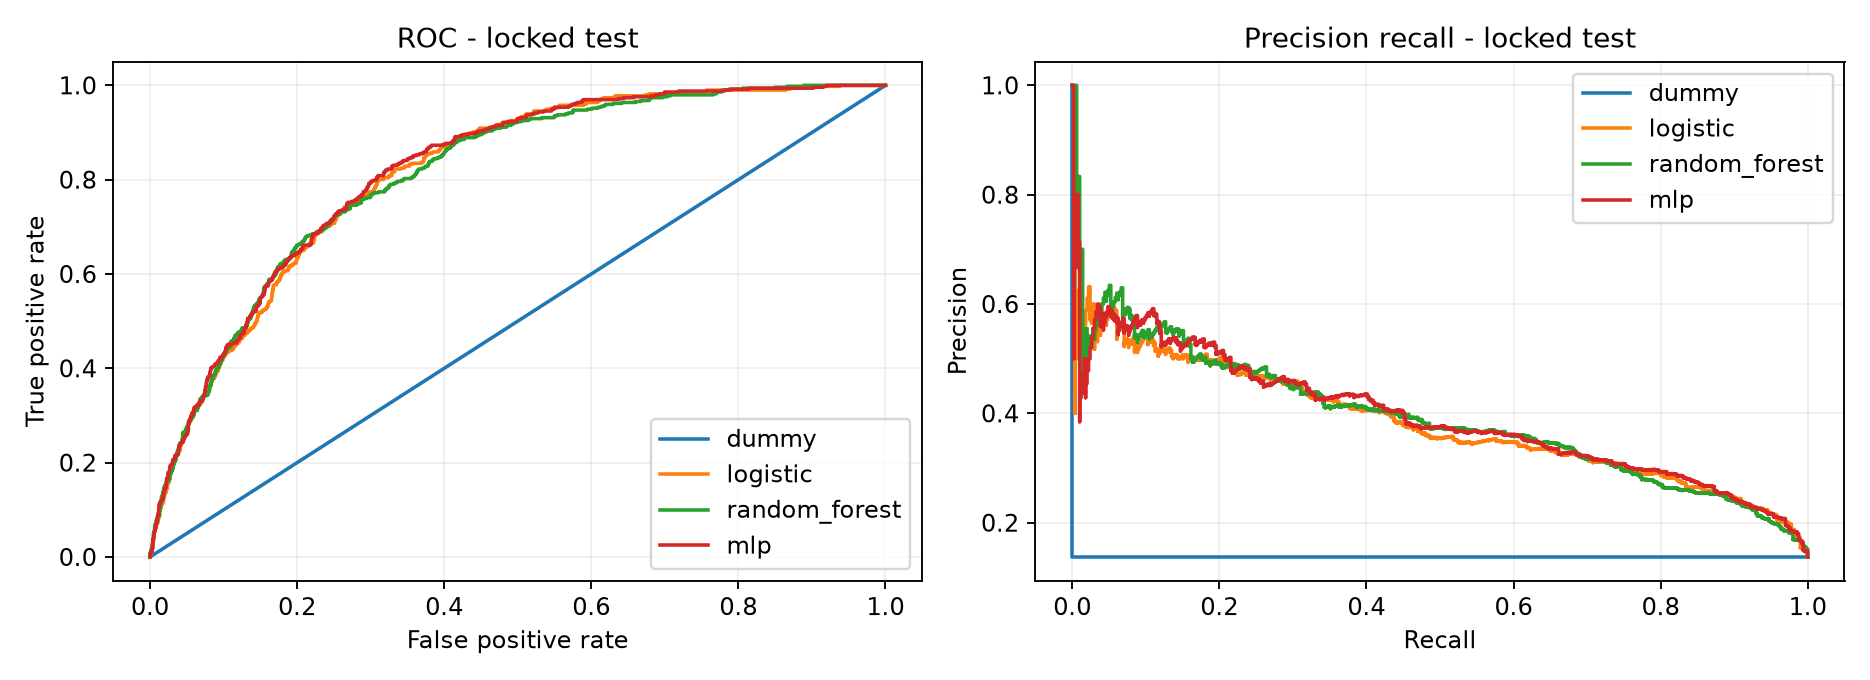

In [6]:
display(test_metrics.round(4))
display(Image(filename=str(ARTIFACTS / "figures/training.png")))
display(Image(filename=str(ARTIFACTS / "figures/classification.png")))

## 5 Nạp model đã lưu và đối chiếu từng dòng
Dùng một dòng test để đối chiếu suy luận với prediction CSV, không dùng dòng đó để chọn lại model.

In [7]:
from diabetes_agent.models import RiskModel
model = RiskModel()
stored = pd.read_csv(ARTIFACTS / "predictions_mlp.csv").iloc[0]
sample = frame[frame.row_id == stored.row_id].iloc[0]
prediction = model.predict(sample[FEATURES].to_dict(), "mlp")
print(prediction)
assert abs(prediction["score"] - stored.score) < 1e-6
print("PASS: nạp weight và suy luận khớp prediction đã xuất.")

{'model': 'mlp', 'score': 0.06837016344070435, 'threshold': 0.20500000000000002, 'positive': False, 'meaning': 'Điểm mô hình cho nhãn gộp tiền tiểu đường/tiểu đường trong khảo sát UCI; không phải xác suất mắc bệnh trong tương lai.'}
PASS: nạp weight và suy luận khớp prediction đã xuất.


**Tự đọc mã:** `data.py` bảo vệ nguồn/split; `models.py` chứa vòng mini-batch, early stopping và export. Báo cáo ghi số liệu lấy từ `artifacts/metrics_test.csv`; không lấy kết quả mẫu từ tài liệu tham khảo.